In [4]:
import pandas as pd

In [5]:
df = pd.read_csv("CarPrice_Assignment (1).csv")

df.head()


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [6]:

print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (205, 26)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        2

In [ ]:
Dataset

In [7]:
print("Dataset Shape:", df.shape)

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (205, 26)
Missing Values:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64
Duplicate Rows: 0


In [ ]:
Unnecessary column

In [8]:
df = df.drop(columns=["car_ID"])

print(df.shape)

(205, 25)


In [ ]:
CarName

In [9]:
print(df["CarName"].head(10))
print("Unique car names:", df["CarName"].nunique())


0          alfa-romero giulia
1         alfa-romero stelvio
2    alfa-romero Quadrifoglio
3                 audi 100 ls
4                  audi 100ls
5                    audi fox
6                  audi 100ls
7                   audi 5000
8                   audi 4000
9         audi 5000s (diesel)
Name: CarName, dtype: object
Unique car names: 147


In [ ]:
Target variable

In [10]:
print(df["price"].describe())


count      205.000000
mean     13276.710571
std       7988.852332
min       5118.000000
25%       7788.000000
50%      10295.000000
75%      16503.000000
max      45400.000000
Name: price, dtype: float64


In [ ]:
Missing values, duplicates

In [11]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("Duplicate Rows:")
print(df.duplicated().sum())


Missing Values:
0
Duplicate Rows:
0


In [ ]:
Categorical columns

In [12]:
df["CarName"] = df["CarName"].str.split().str[0]

print(df.select_dtypes(include="object").columns.tolist())

['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


In [ ]:
Categorical Encoding

In [13]:
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

print("Original Shape:", df.shape)
print("Encoded Shape:", df_encoded.shape)

df_encoded.head()


Original Shape: (205, 25)
Encoded Shape: (205, 71)


,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,...,cylindernumber_three,cylindernumber_twelve,cylindernumber_two,fuelsystem_2bbl,fuelsystem_4bbl,fuelsystem_idi,fuelsystem_mfi,fuelsystem_mpfi,fuelsystem_spdi,fuelsystem_spfi
0,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,...,0,0,0,0,0,0,0,1,0,0
1,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,...,0,0,0,0,0,0,0,1,0,0
2,1,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,...,0,0,0,0,0,0,0,1,0,0
3,2,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,...,0,0,0,0,0,0,0,1,0,0
4,2,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,...,0,0,0,0,0,0,0,1,0,0


In [ ]:
X, y

In [14]:

X = df_encoded.drop("price", axis=1)
y = df_encoded["price"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)


X Shape: (205, 70)
y Shape: (205,)


In [ ]:
Train/Test Split

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (164, 70)
Testing data: (41, 70)


In [ ]:
Linear Regression Model Training

In [14]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model training completed!")


Linear Regression model training completed!


In [ ]:
 Model Prediction

In [15]:
y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.head())

print("\nPredicted Prices:")
print(y_pred[:5])


Actual Prices:
15     30760.000
9      17859.167
100     9549.000
132    11850.000
68     28248.000
Name: price, dtype: float64

Predicted Prices:
[29739.106342   21868.91989221 11144.60848204 12423.06191096
 30334.38840229]


In [ ]:
Model Evaluation

In [16]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("R2 Score:", round(r2, 3))
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))


R2 Score: 0.916
MAE: 1733.39
MSE: 6600950.84


In [ ]:
Decision Tree Regressor

In [17]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree model training completed!")

dt_pred = dt_model.predict(X_test)


Decision Tree model training completed!


In [ ]:
Decision Tree Evaluation

In [18]:
dt_r2 = r2_score(y_test, dt_pred)
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)

print("Decision Tree R2 Score:", round(dt_r2, 3))
print("Decision Tree MAE:", round(dt_mae, 2))
print("Decision Tree MSE:", round(dt_mse, 2))


Decision Tree R2 Score: 0.908
Decision Tree MAE: 1798.48
Decision Tree MSE: 7276978.44


In [ ]:
Random Forest Regressor

In [19]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model training completed!")

rf_pred = rf_model.predict(X_test)


Random Forest model training completed!


In [ ]:
Random Forest Evaluation

In [20]:
rf_r2 = r2_score(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)

print("Random Forest R2 Score:", round(rf_r2, 3))
print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest MSE:", round(rf_mse, 2))


Random Forest R2 Score: 0.958
Random Forest MAE: 1287.9
Random Forest MSE: 3333544.23


In [ ]:
Gradient Boosting Regressor

In [21]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(random_state=42)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model training completed!")

gb_pred = gb_model.predict(X_test)


Gradient Boosting model training completed!


In [ ]:
Gradient Boosting Evaluation

In [22]:
gb_r2 = r2_score(y_test, gb_pred)
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_mse = mean_squared_error(y_test, gb_pred)

print("Gradient Boosting R2 Score:", round(gb_r2, 3))
print("Gradient Boosting MAE:", round(gb_mae, 2))
print("Gradient Boosting MSE:", round(gb_mse, 2))


Gradient Boosting R2 Score: 0.928
Gradient Boosting MAE: 1692.53
Gradient Boosting MSE: 5708107.41


In [ ]:
SVR (Support Vector Regression)

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data scaling completed!")


Data scaling completed!


In [ ]:
SVR Model Training

In [24]:
from sklearn.svm import SVR

svr_model = SVR(kernel="rbf")

svr_model.fit(X_train_scaled, y_train)

print("SVR model training completed!")

svr_pred = svr_model.predict(X_test_scaled)


SVR model training completed!


In [ ]:
SVR Evaluation

In [25]:

svr_r2 = r2_score(y_test, svr_pred)
svr_mae = mean_absolute_error(y_test, svr_pred)
svr_mse = mean_squared_error(y_test, svr_pred)

print("SVR R2 Score:", round(svr_r2, 3))
print("SVR MAE:", round(svr_mae, 2))
print("SVR MSE:", round(svr_mse, 2))


SVR R2 Score: -0.101
SVR MAE: 5701.44
SVR MSE: 86890173.85


In [ ]:
Compare All 5 Models

In [26]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "SVR"
    ],
    "R2 Score": [
        r2, dt_r2, rf_r2, gb_r2, svr_r2
    ],
    "MAE": [
        mae, dt_mae, rf_mae, gb_mae, svr_mae
    ],
    "MSE": [
        mse, dt_mse, rf_mse, gb_mse, svr_mse
    ]
})

results = results.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

results


,Model,R2 Score,MAE,MSE
0,Random Forest,0.957773,1287.900053,3.333544e+06
1,Gradient Boosting,0.927694,1692.533882,5.708107e+06
2,Linear Regression,0.916384,1733.390417,6.600951e+06
3,Decision Tree,0.907821,1798.479683,7.276978e+06
4,SVR,-0.100656,5701.439470,8.689017e+07


In [ ]:
Feature Importance

In [30]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance


,Feature,Importance
0,enginesize,5.517608e-01
1,curbweight,2.927936e-01
2,highwaympg,4.577051e-02
3,horsepower,3.201251e-02
4,carwidth,1.432641e-02
...,...,...
65,enginelocation_rear,2.061153e-06
66,CarName_toyouta,1.877184e-06
67,enginetype_dohcv,3.945774e-08
68,cylindernumber_three,0.000000e+00


In [ ]:
Feature Importance Graph

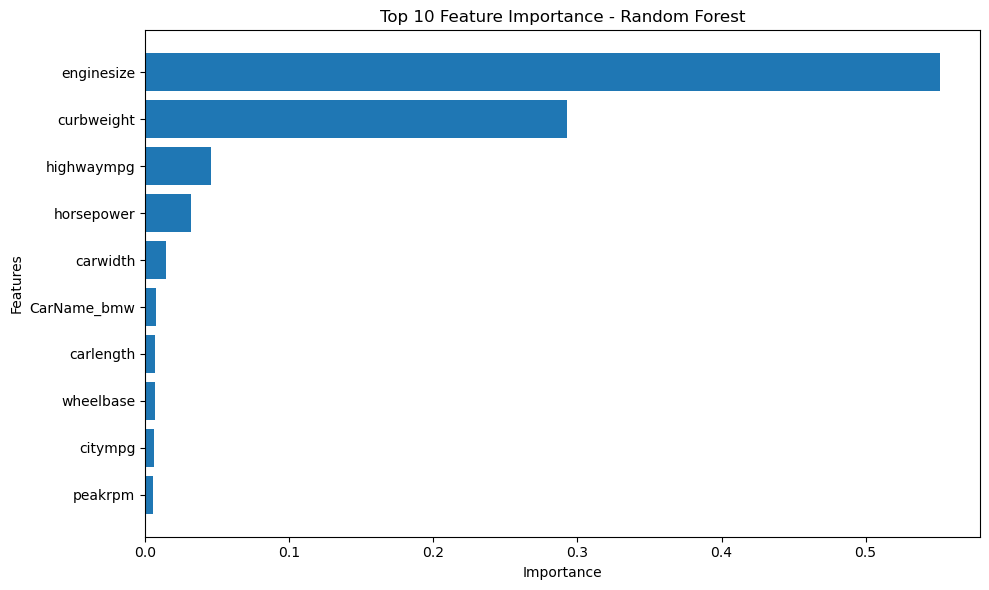

In [31]:

import matplotlib.pyplot as plt

top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Feature Importance - Random Forest")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [ ]:
Model Comparison Graph

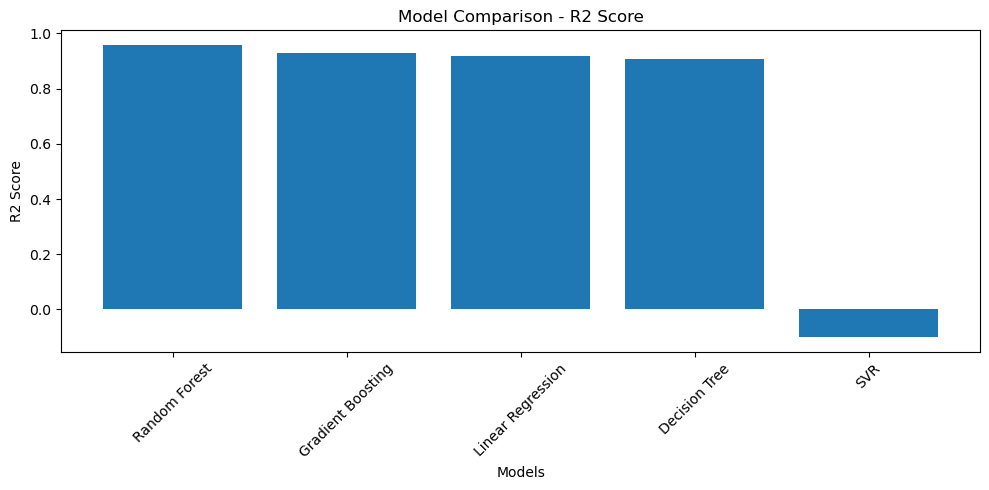

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    results["Model"],
    results["R2 Score"]
)

plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.title("Model Comparison - R2 Score")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
Actual Price vs Predicted Price Graph

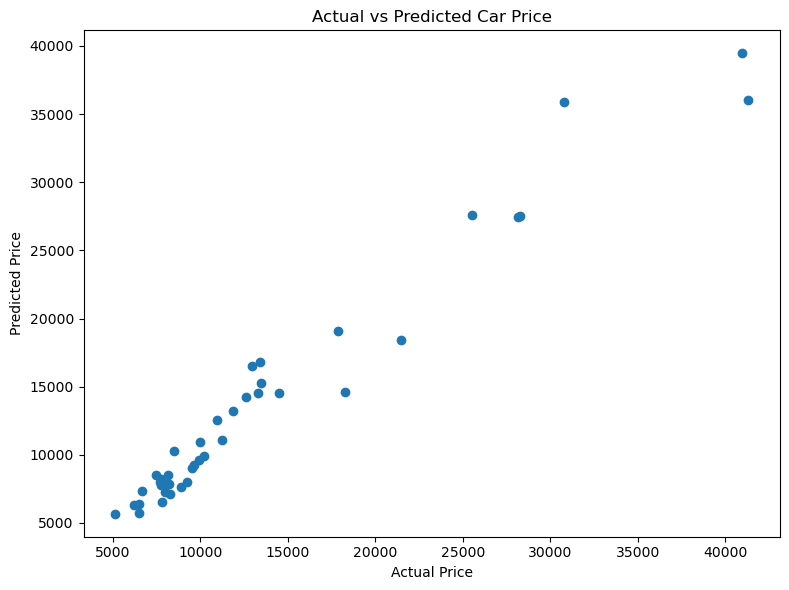

In [33]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Price")

plt.tight_layout()
plt.show()


In [ ]:
Model save

In [34]:
import joblib

joblib.dump(rf_model, "car_price_model.pkl")

joblib.dump(list(X_train.columns), "feature_columns.pkl")

print("Model saved successfully!")
print("Feature columns saved successfully!")


Model saved successfully!
Feature columns saved successfully!


In [ ]:
Hyperparameter Tuning

In [37]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf_model = grid_search.best_estimator_
tuned_pred = best_rf_model.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("Before Tuning R2:", r2_score(y_test, rf_pred))
print("After Tuning R2:", r2_score(y_test, tuned_pred))
print("After Tuning MSE:", mean_squared_error(y_test, tuned_pred))
print("After Tuning MAE:", mean_absolute_error(y_test, tuned_pred))


Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Before Tuning R2: 0.9577733158858429
After Tuning R2: 0.9577733158858429
After Tuning MSE: 3333544.232386725
After Tuning MAE: 1287.900052845528


In [ ]:
Tuned Model Save

In [38]:
import joblib

joblib.dump(best_rf_model, "car_price_model.pkl")

joblib.dump(list(X_train.columns), "feature_columns.pkl")

print("Tuned model saved successfully!")
print("Feature columns saved successfully!")


Tuned model saved successfully!
Feature columns saved successfully!


Conclusion

In this project, five regression algorithms were implemented to predict car prices: Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor, and Support Vector Regressor.

The models were evaluated using R-squared, Mean Squared Error (MSE), and Mean Absolute Error (MAE). Random Forest Regressor performed best, achieving an R-squared score of approximately 0.958, an MAE of 1287.90, and an MSE of 3333544.23.

Feature importance analysis showed that engine size and curb weight were the most significant features affecting car prices.

Hyperparameter tuning was performed using GridSearchCV. The best parameters were n_estimators=100, max_depth=None, and min_samples_split=2. The model's performance remained unchanged after tuning.

Therefore, Random Forest Regressor was selected as the best-performing model for this dataset.